In [45]:
import numpy as np
import pandas as pd
import pickle
from tensorflow.keras.models import load_model

In [67]:
from tensorflow.keras.models import load_model
import tensorflow.keras.losses

custom_objects = {"mse": tensorflow.keras.losses.MeanSquaredError()}

model = load_model('/content/Final_TP_Prediction_Model.h5', custom_objects=custom_objects)

In [68]:
with open('/content/scaler_TP.pkl', 'rb') as f:
    scaler = pickle.load(f)

In [69]:
import numpy as np
import pandas as pd

def generate_dummy_tp_data():
    date_rng = pd.date_range(start="2025-03-01", periods=168, freq="H")  # 1 week of hourly data

    day_hours = date_rng.hour
    base_pressure = 35 - 1.5 * np.sin(2 * np.pi * day_hours / 24)  # Daily variation

    weekly_trend = 0.5 * np.sin(2 * np.pi * date_rng.dayofweek / 7)  # Weekly cycle

    temperature_effect = np.where((7 <= day_hours) & (day_hours <= 17), -0.3, 0)  # Lower TP in heat

    np.random.seed(42)
    noise = np.random.normal(0, 0.2, 168)  # Small noise

    tyre_pressure = base_pressure + weekly_trend + temperature_effect + noise

    df = pd.DataFrame({"datetime": date_rng, "Tyre_Pressure_PSI": tyre_pressure})

    return df

# Example usage
df = generate_dummy_tp_data()
print(df.head())

             datetime  Tyre_Pressure_PSI
0 2025-03-01 00:00:00          34.611879
1 2025-03-01 01:00:00          34.096655
2 2025-03-01 02:00:00          33.892074
3 2025-03-01 03:00:00          33.756482
4 2025-03-01 04:00:00          33.166667


<ipython-input-69-8edafa7a7730>:5: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  date_rng = pd.date_range(start="2025-03-01", periods=168, freq="H")  # 1 week of hourly data


In [70]:
df_new = generate_dummy_tp_data()
df_new.head()

<ipython-input-69-8edafa7a7730>:5: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  date_rng = pd.date_range(start="2025-03-01", periods=168, freq="H")  # 1 week of hourly data


,datetime,Tyre_Pressure_PSI
0,2025-03-01 00:00:00,34.611879
1,2025-03-01 01:00:00,34.096655
2,2025-03-01 02:00:00,33.892074
3,2025-03-01 03:00:00,33.756482
4,2025-03-01 04:00:00,33.166667


In [71]:
df_new.describe()

,datetime,Tyre_Pressure_PSI
count,168,168.000000
mean,2025-03-04 11:30:00,34.854677
min,2025-03-01 00:00:00,32.819603
25%,2025-03-02 17:45:00,33.856649
50%,2025-03-04 11:30:00,34.804074
75%,2025-03-06 05:15:00,35.764923
max,2025-03-07 23:00:00,37.129001
std,NaN,1.151323


In [72]:
# Load new dataset (make sure it has at least 168 hours of data)
df_new['datetime'] = pd.to_datetime(df_new['datetime'])
df_new.set_index('datetime', inplace=True)

In [73]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 168 entries, 2025-03-01 00:00:00 to 2025-03-07 23:00:00
Data columns (total 1 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Tyre_Pressure_PSI  168 non-null    float64
dtypes: float64(1)
memory usage: 2.6 KB


In [74]:
import numpy as np
import pandas as pd

def create_features(df):
    """
    Enhances the tyre-pressure DataFrame with various time-based,
    cyclical, and lag/rolling features.

    Assumptions:
    1) df.index is a DateTimeIndex at hourly frequency.
    2) The main column is 'tyre_pressure' in PSI.
    """
    # ------------------------------------------------------------------
    # 1. Basic Time-Based Features
    # ------------------------------------------------------------------
    df["Hour"] = df.index.hour
    df["DayOfWeek"] = df.index.dayofweek  # Monday=0, Sunday=6
    df["Month"] = df.index.month

    # Weekend and Rush Hour flags (example logic)
    df["isWeekend"] = df["DayOfWeek"].apply(lambda x: 1 if x >= 5 else 0)
    df["isRushHour"] = df["Hour"].apply(lambda x: 1 if 7 <= x <= 9 or 17 <= x <= 19 else 0)

    # ------------------------------------------------------------------
    # 2. Cyclical Encoding for Hour, Day of Week, Month
    # ------------------------------------------------------------------
    df['hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)

    df['day_sin'] = np.sin(2 * np.pi * df['DayOfWeek'] / 7)
    df['day_cos'] = np.cos(2 * np.pi * df['DayOfWeek'] / 7)

    df['month_sin'] = np.sin(2 * np.pi * (df['Month'] - 1) / 12)
    df['month_cos'] = np.cos(2 * np.pi * (df['Month'] - 1) / 12)

    # ------------------------------------------------------------------
    # 3. Lag and Rolling Features (using tyre_pressure)
    # ------------------------------------------------------------------
    # 24-hour lag (yesterday at the same hour)
    df['tp_lag_24h'] = df['Tyre_Pressure_PSI'].shift(24)

    # 72-hour rolling average (~3 days)
    df['tp_rolling_avg_3d'] = df['Tyre_Pressure_PSI'].rolling(window=72).mean()

    # ------------------------------------------------------------------
    # 4. Cleanup: Drop Unwanted Columns & Rows with NaNs
    # ------------------------------------------------------------------
    # We drop the raw Hour/DayOfWeek/Month columns now that we've
    # extracted cyclical features
    df.drop(['Hour', 'DayOfWeek', 'Month'], axis=1, inplace=True)

    # Drop any rows that became NaN due to shift or rolling
    df.dropna(inplace=True)

    return df

In [75]:
# Apply feature engineering function
df = create_features(df_new)

# Define features and target (replacing Engine_Temperature with tyre_pressure)
features = ['Tyre_Pressure_PSI', 'isWeekend', 'isRushHour',
            'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
            'month_sin', 'month_cos', 'tp_lag_24h',
            'tp_rolling_avg_3d']

# Define the target variable (the value we want to predict)
target = 'Tyre_Pressure_PSI'

In [76]:
latest_data = df_new[features].iloc[-56:]  # Last 56 hours

In [77]:
# Scale data using saved scaler
latest_scaled = scaler.transform(latest_data)
latest_scaled = np.expand_dims(latest_scaled, axis=0)  # Reshape for LSTM

In [78]:
# Predict next 24 hours
predictions_scaled = model.predict(latest_scaled)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 836ms/step


In [79]:
# Function to inverse scale predictions
def inverse_scale_predictions(scaled_predictions, scaler, feature_index=0):
    n_samples, n_steps = scaled_predictions.shape
    dummy = np.zeros((n_samples * n_steps, len(features)))
    dummy[:, feature_index] = scaled_predictions.flatten()

    inverse_scaled = scaler.inverse_transform(dummy)

    return inverse_scaled[:, feature_index].reshape(n_samples, n_steps)

In [80]:
# Convert predictions back to original temperature scale
predictions = inverse_scale_predictions(predictions_scaled, scaler)

In [88]:
# Generate timestamps for the next 24 hours
future_timestamps = pd.date_range(start=df_new.index[-1], periods=9, freq='H')[1:]

<ipython-input-88-c3f978dee180>:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  future_timestamps = pd.date_range(start=df_new.index[-1], periods=9, freq='H')[1:]


In [89]:
predictions.shape

(1, 8)

In [93]:
# Create DataFrame with timestamps and predicted values
predictions_df = pd.DataFrame({'datetime': future_timestamps, 'Tyre_Pressure_PSI': predictions.flatten()})

print(predictions_df)

             datetime  Tyre_Pressure_PSI
0 2025-03-08 00:00:00          32.958866
1 2025-03-08 01:00:00          32.515794
2 2025-03-08 02:00:00          32.330486
3 2025-03-08 03:00:00          31.601228
4 2025-03-08 04:00:00          32.524266
5 2025-03-08 05:00:00          32.010741
6 2025-03-08 06:00:00          32.337428
7 2025-03-08 07:00:00          32.100252


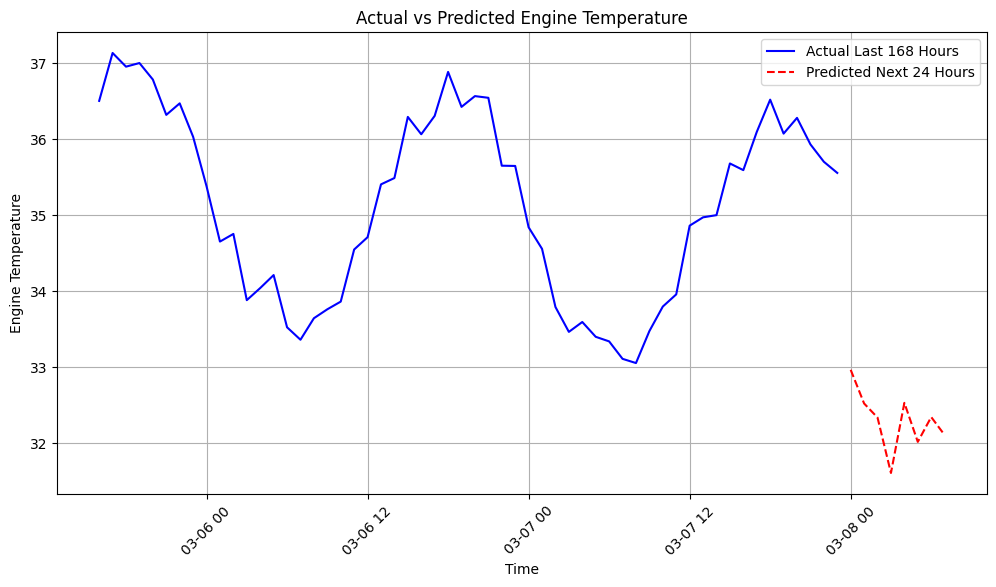

In [95]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(df_new.index[-56:], df_new['Tyre_Pressure_PSI'].iloc[-56:], label="Actual Last 168 Hours", color="blue")
plt.plot(predictions_df['datetime'], predictions_df['Tyre_Pressure_PSI'], label="Predicted Next 24 Hours", color="red", linestyle='dashed')
plt.xlabel("Time")
plt.ylabel("Engine Temperature")
plt.title("Actual vs Predicted Engine Temperature")
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()